# EDA Penjualan Balaji Fast Food

Notebook ini memuat proses audit, pembersihan, validasi, dan eksplorasi data transaksi. Jalankan dari folder yang berisi `Balaji Fast Food Sales Raw.csv`. Hasil bersih disimpan sebagai `Balaji Fast Food Sales.csv`; kolom `transaction_type` yang tidak tercatat dipertahankan sebagai `Unknown`, bukan ditebak.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

SOURCE = Path('Balaji Fast Food Sales Raw.csv')
OUTPUT = Path('Balaji Fast Food Sales.csv')
raw = pd.read_csv(SOURCE)
print(f'Ukuran awal: {raw.shape[0]:,} baris x {raw.shape[1]} kolom')
display(raw.isna().sum().rename('missing').to_frame())
display(raw.head())

Ukuran awal: 1,000 baris x 13 kolom


,missing
order_id,0
date,0
item_name,0
item_type,0
item_price,0
quantity,0
transaction_amount,0
transaction_type,107
received_by,0
time_of_sale,0


,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,1,7/3/2022,Aalopuri,Fastfood,20,13,260,NaN,Mr.,Night,NaN,NaN,NaN
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon,NaN,NaN,NaN
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon,NaN,NaN,NaN
3,4,2/3/2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night,NaN,NaN,NaN
4,5,10/2/2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening,NaN,NaN,NaN


## Pembersihan dan validasi

Teks dibersihkan dari spasi tepi; teks kosong diperlakukan sebagai missing. Kolom yang seluruh isinya kosong dibuang. Tanggal sumber dibaca dalam format bulan/hari/tahun, disimpan sebagai ISO `YYYY-MM-DD`, dan diturunkan menjadi `month` (`YYYY-MM`). Tidak ada transaksi yang dihapus.

In [2]:
df = raw.copy()
for column in df.select_dtypes(include='object').columns:
    df[column] = df[column].str.strip().replace('', pd.NA)

empty_columns = df.columns[df.isna().all()].tolist()
df = df.drop(columns=empty_columns)
missing_payment = int(df['transaction_type'].isna().sum())
df['transaction_type'] = df['transaction_type'].fillna('Unknown')
parsed_date = pd.to_datetime(df['date'], format='%m/%d/%Y', errors='raise')
df['date'] = parsed_date.dt.strftime('%Y-%m-%d')
df['month'] = parsed_date.dt.to_period('M').astype(str)

clean_columns = [
    'order_id', 'date', 'item_name', 'item_type', 'item_price', 'quantity',
    'transaction_amount', 'transaction_type', 'received_by', 'time_of_sale', 'month'
]
df = df[clean_columns]

assert len(df) == len(raw), 'Jumlah baris berubah secara tidak terduga.'
assert df['order_id'].is_unique, 'order_id tidak unik.'
assert not df.duplicated().any(), 'Ada baris duplikat.'
assert df[['order_id', 'date', 'item_name', 'item_type', 'item_price', 'quantity',
           'transaction_amount', 'transaction_type', 'received_by', 'time_of_sale',
           'month']].notna().all().all(), 'Masih terdapat missing value.'
assert (df['transaction_amount'] == df['item_price'] * df['quantity']).all(), \
    'Ada transaction_amount yang berbeda dari item_price x quantity.'

df.to_csv(OUTPUT, index=False, encoding='utf-8')
cleaning_log = pd.DataFrame([
    ('Baris dipertahankan', len(raw), len(df)),
    ('Kolom kosong dibuang', len(empty_columns), 0),
    ('transaction_type kosong diisi Unknown', missing_payment, 0),
    ('Baris duplikat dihapus', 0, 0),
], columns=['Tindakan', 'Sebelum / terdampak', 'Sesudah'])
display(cleaning_log)
print(f'Kolom kosong dibuang: {empty_columns}')
print(f'Dataset bersih tersimpan: {OUTPUT.resolve()}')

,Tindakan,Sebelum / terdampak,Sesudah
0,Baris dipertahankan,1000,1000
1,Kolom kosong dibuang,3,0
2,transaction_type kosong diisi Unknown,107,0
3,Baris duplikat dihapus,0,0


Kolom kosong dibuang: ['Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']
Dataset bersih tersimpan: D:\Document\Excel\DataSet Porto\Restourant (Ms Excel)\Balaji Fast Food Sales.csv


## Ringkasan EDA

Semua nominal menggunakan satuan yang tercatat di sumber; sumber tidak menyebutkan mata uang. `transaction_amount` diperlakukan sebagai nilai penjualan per baris transaksi.

In [3]:
sales = pd.read_csv(OUTPUT, parse_dates=['date'])
overview = pd.DataFrame({
    'Metrik': ['Jumlah transaksi', 'Jumlah unit', 'Total pendapatan',
               'Rata-rata nilai transaksi', 'Median nilai transaksi',
               'Tanggal pertama', 'Tanggal terakhir', 'Tanggal dengan transaksi'],
    'Nilai': [len(sales), sales['quantity'].sum(), sales['transaction_amount'].sum(),
              sales['transaction_amount'].mean(), sales['transaction_amount'].median(),
              sales['date'].min().date(), sales['date'].max().date(), sales['date'].nunique()]
})
display(overview)

product = sales.groupby(['item_name', 'item_type'], as_index=False).agg(
    transactions=('order_id', 'size'), quantity=('quantity', 'sum'),
    revenue=('transaction_amount', 'sum'), unit_price=('item_price', 'first'),
    distinct_prices=('item_price', 'nunique')
)
product['revenue_share_pct'] = product['revenue'] / sales['transaction_amount'].sum() * 100
display(product.sort_values('revenue', ascending=False))

category = sales.groupby('item_type', as_index=False).agg(
    transactions=('order_id', 'size'), quantity=('quantity', 'sum'),
    revenue=('transaction_amount', 'sum')
)
category['revenue_share_pct'] = category['revenue'] / sales['transaction_amount'].sum() * 100
display(category)

payment = sales.groupby('transaction_type', as_index=False).agg(
    transactions=('order_id', 'size'), revenue=('transaction_amount', 'sum')
)
payment['transaction_share_pct'] = payment['transactions'] / len(sales) * 100
payment['revenue_share_pct'] = payment['revenue'] / sales['transaction_amount'].sum() * 100
display(payment)

,Metrik,Nilai
0,Jumlah transaksi,1000
1,Jumlah unit,8162
2,Total pendapatan,275230
3,Rata-rata nilai transaksi,275.23
4,Median nilai transaksi,240.00
5,Tanggal pertama,2022-04-01
6,Tanggal terakhir,2023-03-30
7,Tanggal dengan transaksi,348


,item_name,item_type,transactions,quantity,revenue,unit_price,distinct_prices,revenue_share_pct
4,Sandwich,Fastfood,129,1097,65820,60,1,23.91
2,Frankie,Fastfood,139,1150,57500,50,1,20.89
1,Cold coffee,Beverages,161,1361,54440,40,1,19.78
5,Sugarcane juice,Beverages,153,1278,31950,25,1,11.61
3,Panipuri,Fastfood,150,1226,24520,20,1,8.91
0,Aalopuri,Fastfood,134,1044,20880,20,1,7.59
6,Vadapav,Fastfood,134,1006,20120,20,1,7.31


,item_type,transactions,quantity,revenue,revenue_share_pct
0,Beverages,314,2639,86390,31.39
1,Fastfood,686,5523,188840,68.61


,transaction_type,transactions,revenue,transaction_share_pct,revenue_share_pct
0,Cash,476,132840,47.60,48.27
1,Online,417,110595,41.70,40.18
2,Unknown,107,31795,10.70,11.55


In [4]:
monthly = sales.groupby('month', as_index=False).agg(
    transactions=('order_id', 'size'), quantity=('quantity', 'sum'),
    revenue=('transaction_amount', 'sum')
)
monthly['revenue_per_transaction'] = monthly['revenue'] / monthly['transactions']
monthly['revenue_mom_pct'] = monthly['revenue'].pct_change() * 100
display(monthly)

daypart = sales.groupby('time_of_sale', as_index=False).agg(
    transactions=('order_id', 'size'), quantity=('quantity', 'sum'),
    revenue=('transaction_amount', 'sum')
)
daypart['average_transaction'] = daypart['revenue'] / daypart['transactions']
display(daypart.sort_values('revenue', ascending=False))

weekday = sales.assign(weekday=sales['date'].dt.day_name()).groupby('weekday', as_index=False).agg(
    transactions=('order_id', 'size'), revenue=('transaction_amount', 'sum')
)
display(weekday.sort_values('revenue', ascending=False))

,month,transactions,quantity,revenue,revenue_per_transaction,revenue_mom_pct
0,2022-04,66,503,17670,267.73,NaN
1,2022-05,100,826,26570,265.70,50.37
2,2022-06,68,482,17335,254.93,-34.76
3,2022-07,79,598,19490,246.71,12.43
4,2022-08,90,743,22305,247.83,14.44
5,2022-09,73,554,18640,255.34,-16.43
6,2022-10,98,812,27205,277.60,45.95
7,2022-11,82,682,22900,279.27,-15.82
8,2022-12,90,754,23460,260.67,2.45
9,2023-01,90,788,28670,318.56,22.21


,time_of_sale,transactions,quantity,revenue,average_transaction
4,Night,205,1759,62075,302.80
0,Afternoon,205,1714,56345,274.85
3,Morning,190,1574,53730,282.79
1,Evening,201,1540,52355,260.47
2,Midnight,199,1575,50725,254.90


,weekday,transactions,revenue
3,Sunday,158,43970
1,Monday,141,40930
6,Wednesday,159,40380
4,Thursday,136,39905
2,Saturday,150,37910
5,Tuesday,122,36085
0,Friday,134,36050


## Visualisasi

Grafik berikut membandingkan tren pendapatan bulanan, kontribusi produk, kategori produk, dan waktu penjualan. Grafik bersifat deskriptif; data agregat ini tidak membuktikan penyebab perubahan penjualan.

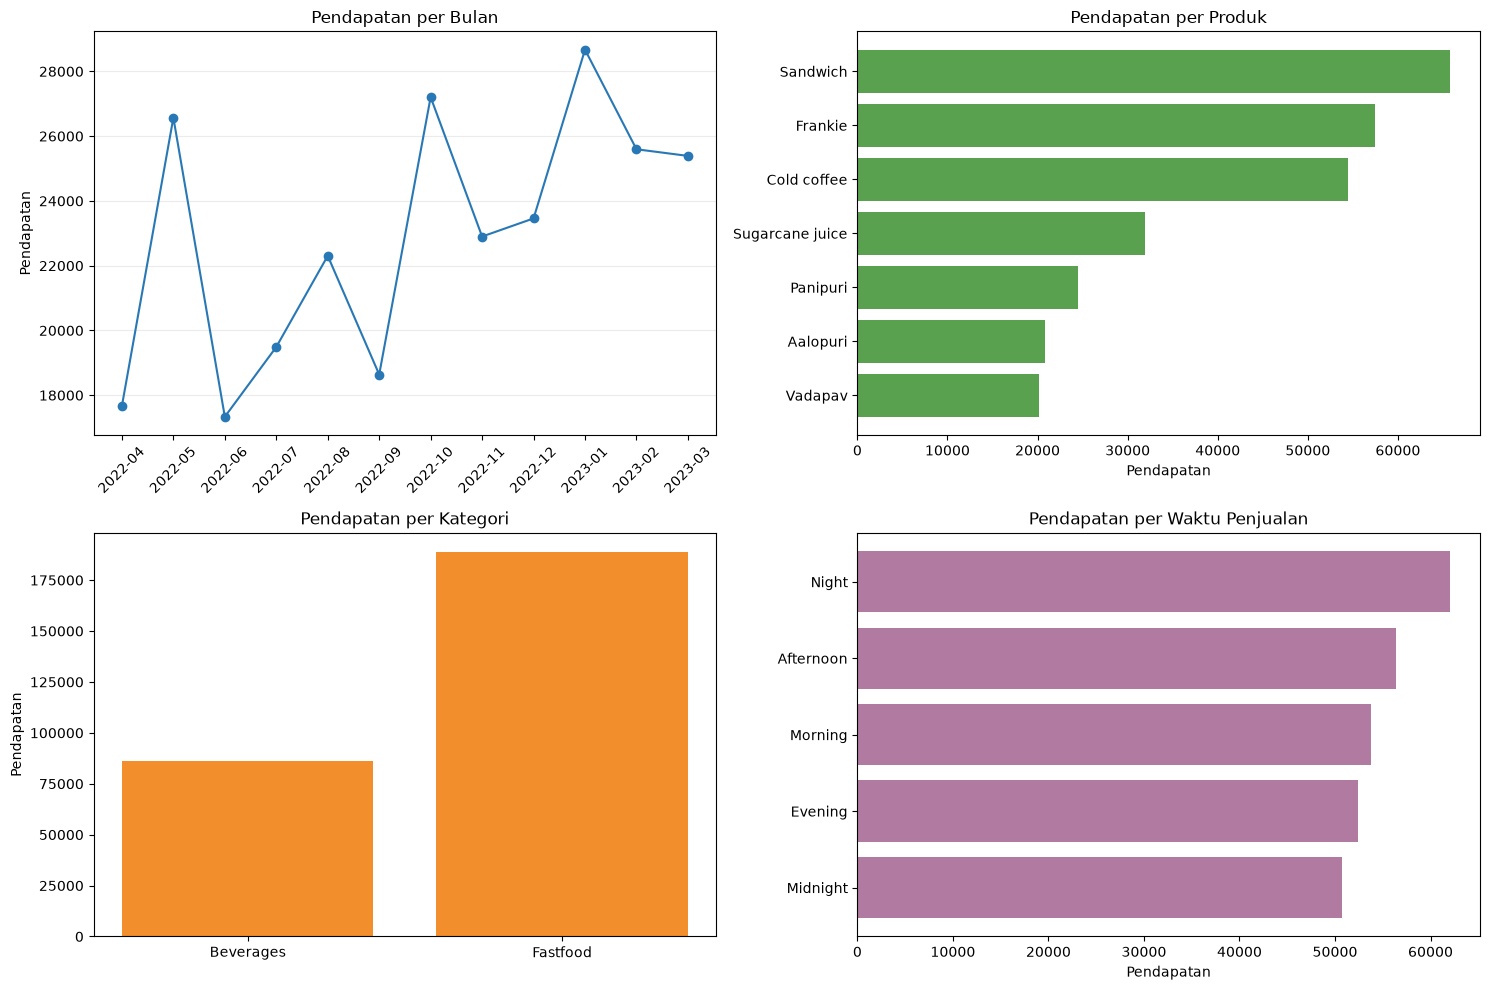

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(monthly['month'], monthly['revenue'], marker='o', color='#2878B5')
axes[0, 0].set_title('Pendapatan per Bulan')
axes[0, 0].set_ylabel('Pendapatan')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(axis='y', alpha=0.25)

product_sorted = product.sort_values('revenue')
axes[0, 1].barh(product_sorted['item_name'], product_sorted['revenue'], color='#59A14F')
axes[0, 1].set_title('Pendapatan per Produk')
axes[0, 1].set_xlabel('Pendapatan')

axes[1, 0].bar(category['item_type'], category['revenue'], color='#F28E2B')
axes[1, 0].set_title('Pendapatan per Kategori')
axes[1, 0].set_ylabel('Pendapatan')

daypart_sorted = daypart.sort_values('revenue')
axes[1, 1].barh(daypart_sorted['time_of_sale'], daypart_sorted['revenue'], color='#B07AA1')
axes[1, 1].set_title('Pendapatan per Waktu Penjualan')
axes[1, 1].set_xlabel('Pendapatan')

fig.tight_layout()
plt.show()